# Assignment 07: Neural Network with Backpropagation
## Compare Backpropagation vs Keras

This notebook trains and tests TwoLayerNetBackprop on MNIST and compares its accuracy with Keras.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import tensorflow.keras as keras

from tensorflow.keras import layers
from tensorflow.keras.datasets import mnist

SEED = 42
keras.utils.set_random_seed(SEED)

print("NumPy version:", np.__version__)
print("TensorFlow version:", tf.__version__)

NumPy version: 1.26.4
TensorFlow version: 2.15.0


### Load MNIST

Load MNIST and prepare the images and labels for training.

In [2]:
(X_train, y_train), (X_test, y_test) = mnist.load_data()

print("Original shapes:")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_test :", X_test.shape)
print("y_test :", y_test.shape)

X_train = X_train.reshape(-1, 28 * 28).astype(np.float32) / 255.0
X_test = X_test.reshape(-1, 28 * 28).astype(np.float32) / 255.0
y_train_onehot = np.eye(10, dtype=np.float32)[y_train]
y_test_onehot = np.eye(10, dtype=np.float32)[y_test]

print("\nPrepared training inputs:", X_train.shape)
print("Prepared testing inputs:", X_test.shape)
print("One-hot training labels:", y_train_onehot.shape)

Original shapes:
X_train: (60000, 28, 28)
y_train: (60000,)
X_test : (10000, 28, 28)
y_test : (10000,)



Prepared training inputs: (60000, 784)
Prepared testing inputs: (10000, 784)
One-hot training labels: (60000, 10)


### TwoLayerNetBackprop

Implement forward propagation and backpropagation for a two-layer neural network.

In [3]:
class TwoLayerNetBackprop:
    def __init__(self, input_size=28 * 28, hidden_size=100, output_size=10,
                 weight_init_std=0.01, seed=42, dtype=np.float32):
        rng = np.random.default_rng(seed)
        self.params = {
            "W1": (weight_init_std * rng.standard_normal(
                (input_size, hidden_size))).astype(dtype),
            "b1": np.zeros(hidden_size, dtype=dtype),
            "W2": (weight_init_std * rng.standard_normal(
                (hidden_size, output_size))).astype(dtype),
            "b2": np.zeros(output_size, dtype=dtype)
        }

    def relu(self, x):
        return np.maximum(0, x)

    def relu_grad(self, x):
        return (x > 0).astype(x.dtype)

    def softmax(self, scores):
        # Subtract the maximum to prevent overflow in exp().
        shifted = scores - np.max(scores, axis=-1, keepdims=True)
        exp_scores = np.exp(shifted)
        return exp_scores / np.sum(exp_scores, axis=-1, keepdims=True)

    def forward(self, x):
        '''Return the intermediate values needed for backpropagation.'''
        x = np.atleast_2d(x)
        a1 = x @ self.params["W1"] + self.params["b1"]
        z1 = self.relu(a1)
        a2 = z1 @ self.params["W2"] + self.params["b2"]
        return a1, z1, a2

    def predict(self, x):
        '''Return one row of class probabilities per image.'''
        _, _, scores = self.forward(x)
        return self.softmax(scores)

    def loss(self, x, y):
        '''Mean cross-entropy for one-hot labels, using stable log-softmax.'''
        y = np.atleast_2d(y)
        _, _, scores = self.forward(x)
        shifted = scores - np.max(scores, axis=1, keepdims=True)
        log_probabilities = shifted - np.log(
            np.sum(np.exp(shifted), axis=1, keepdims=True)
        )
        return float(-np.sum(y * log_probabilities) / len(y))

    def accuracy(self, x, y):
        '''Classification accuracy using integer labels.'''
        predicted_class = np.argmax(self.predict(x), axis=1)
        return float(np.mean(predicted_class == y))

    def gradient(self, x, y):
        '''Calculate all weight and bias gradients using backpropagation.'''
        x = np.atleast_2d(x)
        y = np.atleast_2d(y)
        batch_size = x.shape[0]

        # Forward propagation.
        a1, z1, a2 = self.forward(x)
        yhat = self.softmax(a2)

        # Output layer: softmax with mean cross-entropy.
        da2 = (yhat - y) / batch_size
        dW2 = z1.T @ da2
        db2 = np.sum(da2, axis=0)

        # Hidden layer: pass the gradient through ReLU.
        dz1 = da2 @ self.params["W2"].T
        da1 = dz1 * self.relu_grad(a1)
        dW1 = x.T @ da1
        db1 = np.sum(da1, axis=0)

        return {"W1": dW1, "b1": db1, "W2": dW2, "b2": db2}

### Check the Gradients

Check the backpropagation gradients against numerical gradients.

In [4]:
check_net = TwoLayerNetBackprop(4, 5, 3, weight_init_std=0.1,
                                seed=SEED, dtype=np.float64)
check_net.params["b1"][:] = [-0.5, 0.5, -0.5, 0.5, 0.5]
check_rng = np.random.default_rng(SEED)
check_x = check_rng.normal(0, 0.2, (3, 4))
check_y = np.eye(3)[[0, 2, 1]]
analytic_gradients = check_net.gradient(check_x, check_y)
h = 1e-5

# Keep finite differences away from ReLU's nondifferentiable point at zero.
assert np.min(np.abs(check_net.forward(check_x)[0])) > 1e-3

for name, parameter in check_net.params.items():
    numerical = np.zeros_like(parameter)
    for index in np.ndindex(parameter.shape):
        original = parameter[index]
        try:
            parameter[index] = original + h
            loss_plus = check_net.loss(check_x, check_y)
            parameter[index] = original - h
            loss_minus = check_net.loss(check_x, check_y)
        finally:
            parameter[index] = original
        numerical[index] = (loss_plus - loss_minus) / (2 * h)

    max_error = np.max(np.abs(numerical - analytic_gradients[name]))
    np.testing.assert_allclose(analytic_gradients[name], numerical,
                               rtol=1e-5, atol=1e-7)
    print(f"{name}: maximum absolute gradient error = {max_error:.2e}")

print("Gradient check passed for all weights and biases.")

W1: maximum absolute gradient error = 1.32e-11
b1: maximum absolute gradient error = 1.10e-11
W2: maximum absolute gradient error = 1.27e-11
b2: maximum absolute gradient error = 1.43e-11
Gradient check passed for all weights and biases.


### Train the NumPy Network

Train the NumPy model for 10 epochs using mini-batch gradient descent.

In [5]:
epochs = 10
learning_rate = 0.1
batch_size = 64

network = TwoLayerNetBackprop(seed=SEED)
initial_weights = [network.params[name].copy()
                   for name in ("W1", "b1", "W2", "b2")]

train_loss_list = []
train_acc_list = []
shuffle_rng = np.random.default_rng(SEED + 1)

print(f"Before training | Loss: {network.loss(X_train, y_train_onehot):.4f} | "
      f"Accuracy: {network.accuracy(X_train, y_train):.2%}")

for epoch in range(epochs):
    indices = shuffle_rng.permutation(len(X_train))

    for start in range(0, len(X_train), batch_size):
        batch = indices[start:start + batch_size]
        gradients = network.gradient(X_train[batch], y_train_onehot[batch])
        for name in network.params:
            network.params[name] -= learning_rate * gradients[name]

    train_loss = network.loss(X_train, y_train_onehot)
    train_accuracy = network.accuracy(X_train, y_train)
    train_loss_list.append(train_loss)
    train_acc_list.append(train_accuracy)

    print(f"Epoch {epoch + 1:2d}/{epochs} | Loss: {train_loss:.4f} | "
          f"Training accuracy: {train_accuracy:.2%}", flush=True)

Before training | Loss: 2.3022 | Accuracy: 12.04%


Epoch  1/10 | Loss: 0.2853 | Training accuracy: 91.87%


Epoch  2/10 | Loss: 0.2026 | Training accuracy: 94.38%


Epoch  3/10 | Loss: 0.1614 | Training accuracy: 95.47%


Epoch  4/10 | Loss: 0.1323 | Training accuracy: 96.28%


Epoch  5/10 | Loss: 0.1132 | Training accuracy: 96.89%


Epoch  6/10 | Loss: 0.1003 | Training accuracy: 97.15%


Epoch  7/10 | Loss: 0.0847 | Training accuracy: 97.72%


Epoch  8/10 | Loss: 0.0958 | Training accuracy: 97.23%


Epoch  9/10 | Loss: 0.0685 | Training accuracy: 98.12%


Epoch 10/10 | Loss: 0.0620 | Training accuracy: 98.30%


### Train the Keras Network

Train a Keras model using the same architecture and training settings.

In [6]:
keras_model = keras.Sequential([
    keras.Input(shape=(28 * 28,)),
    layers.Dense(100, activation="relu"),
    layers.Dense(10, activation="softmax")
])

keras_model.set_weights(initial_weights)
keras_model.compile(
    optimizer=keras.optimizers.SGD(learning_rate=learning_rate, momentum=0.0),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

keras_model.summary()

Model: "sequential"


_________________________________________________________________


 Layer (type)                Output Shape              Param #   


 dense (Dense)               (None, 100)               78500     


 dense_1 (Dense)             (None, 10)                1010      


Total params: 79510 (310.59 KB)


Trainable params: 79510 (310.59 KB)


Non-trainable params: 0 (0.00 Byte)


_________________________________________________________________


In [7]:
keras_train_loss_list = []
keras_train_acc_list = []
keras_shuffle_rng = np.random.default_rng(SEED + 1)

initial_loss, initial_accuracy = keras_model.evaluate(
    X_train, y_train_onehot, batch_size=1024, verbose=0
)
print(f"Before training | Loss: {initial_loss:.4f} | "
      f"Accuracy: {initial_accuracy:.2%}")

for epoch in range(epochs):
    indices = keras_shuffle_rng.permutation(len(X_train))
    keras_model.fit(
        X_train[indices], y_train_onehot[indices],
        epochs=1, batch_size=batch_size, shuffle=False, verbose=0
    )

    train_loss, train_accuracy = keras_model.evaluate(
        X_train, y_train_onehot, batch_size=1024, verbose=0
    )
    keras_train_loss_list.append(train_loss)
    keras_train_acc_list.append(train_accuracy)

    print(f"Epoch {epoch + 1:2d}/{epochs} | Loss: {train_loss:.4f} | "
          f"Training accuracy: {train_accuracy:.2%}", flush=True)

Before training | Loss: 2.3022 | Accuracy: 12.04%

Epoch  1/10 | Loss: 0.2853 | Training accuracy: 91.87%


Epoch  2/10 | Loss: 0.2026 | Training accuracy: 94.37%


Epoch  3/10 | Loss: 0.1615 | Training accuracy: 95.46%


Epoch  4/10 | Loss: 0.1324 | Training accuracy: 96.27%


Epoch  5/10 | Loss: 0.1132 | Training accuracy: 96.89%


Epoch  6/10 | Loss: 0.1002 | Training accuracy: 97.15%


Epoch  7/10 | Loss: 0.0847 | Training accuracy: 97.71%


Epoch  8/10 | Loss: 0.0954 | Training accuracy: 97.26%


Epoch  9/10 | Loss: 0.0688 | Training accuracy: 98.13%


Epoch 10/10 | Loss: 0.0621 | Training accuracy: 98.31%


### Training Loss and Accuracy

Plot the training loss and accuracy for both models.

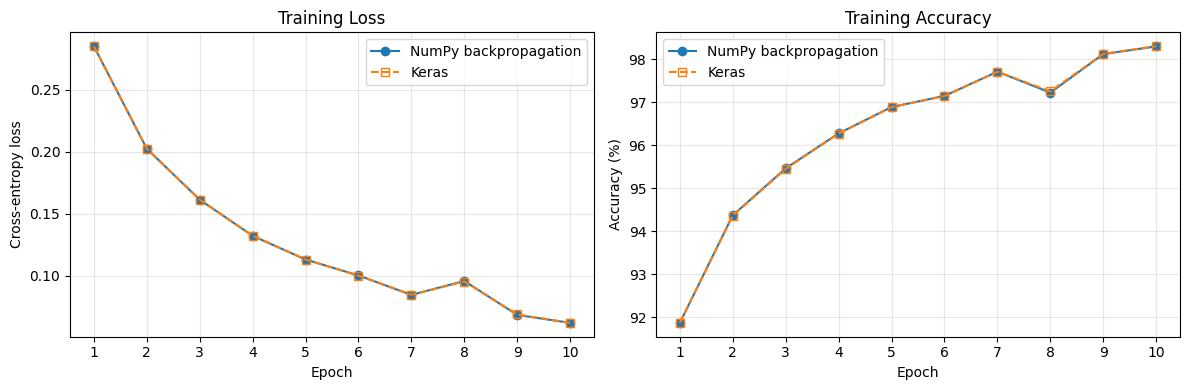

In [8]:
epoch_numbers = np.arange(1, epochs + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(epoch_numbers, train_loss_list, "o-", label="NumPy backpropagation")
axes[0].plot(epoch_numbers, keras_train_loss_list, "s--", label="Keras",
             markerfacecolor="none")
axes[0].set_title("Training Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-entropy loss")

axes[1].plot(epoch_numbers, np.array(train_acc_list) * 100, "o-",
             label="NumPy backpropagation")
axes[1].plot(epoch_numbers, np.array(keras_train_acc_list) * 100, "s--",
             label="Keras", markerfacecolor="none")
axes[1].set_title("Training Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")

for ax in axes:
    ax.set_xticks(epoch_numbers)
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()
plt.close(fig)

### Test Both Models

Evaluate both models on the 10,000 MNIST test images.

In [9]:
numpy_test_probabilities = network.predict(X_test)
numpy_test_predictions = np.argmax(numpy_test_probabilities, axis=1)
numpy_test_loss = network.loss(X_test, y_test_onehot)
numpy_test_accuracy = float(np.mean(numpy_test_predictions == y_test))

keras_test_loss, keras_test_accuracy = keras_model.evaluate(
    X_test, y_test_onehot, batch_size=1024, verbose=0
)
keras_test_probabilities = keras_model.predict(X_test, batch_size=1024, verbose=0)
keras_test_predictions = np.argmax(keras_test_probabilities, axis=1)

results = [
    ("NumPy backpropagation", train_loss_list[-1], train_acc_list[-1],
     numpy_test_loss, numpy_test_accuracy),
    ("Keras", keras_train_loss_list[-1], keras_train_acc_list[-1],
     keras_test_loss, keras_test_accuracy)
]

print(f"{'Approach':<24}{'Train loss':>12}{'Train accuracy':>17}"
      f"{'Test loss':>12}{'Test accuracy':>16}")
print("-" * 81)
for name, train_loss, train_accuracy, test_loss, test_accuracy in results:
    print(f"{name:<24}{train_loss:>12.4f}{train_accuracy:>17.2%}"
          f"{test_loss:>12.4f}{test_accuracy:>16.2%}")

print(f"\nNumPy correct: {np.sum(numpy_test_predictions == y_test):,} / {len(y_test):,}")
print(f"Keras correct: {np.sum(keras_test_predictions == y_test):,} / {len(y_test):,}")

Approach                  Train loss   Train accuracy   Test loss   Test accuracy
---------------------------------------------------------------------------------
NumPy backpropagation         0.0620           98.30%      0.0883          97.21%
Keras                         0.0621           98.31%      0.0884          97.25%

NumPy correct: 9,721 / 10,000
Keras correct: 9,725 / 10,000


### A Single Test Case

Display one test image and compare each model's prediction.

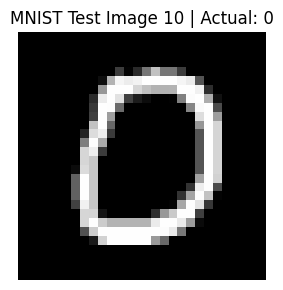

Actual digit: 0
NumPy prediction: 0
Keras prediction: 0


In [10]:
sample = 10
fig, ax = plt.subplots(figsize=(3, 3))
ax.imshow(X_test[sample].reshape(28, 28), cmap="gray", vmin=0, vmax=1)
ax.set_title(f"MNIST Test Image {sample} | Actual: {y_test[sample]}")
ax.axis("off")
plt.tight_layout()
plt.show()
plt.close(fig)

print("Actual digit:", y_test[sample])
print("NumPy prediction:", numpy_test_predictions[sample])
print("Keras prediction:", keras_test_predictions[sample])

### Sample Predictions

Compare both models' predictions on the first 20 test images.

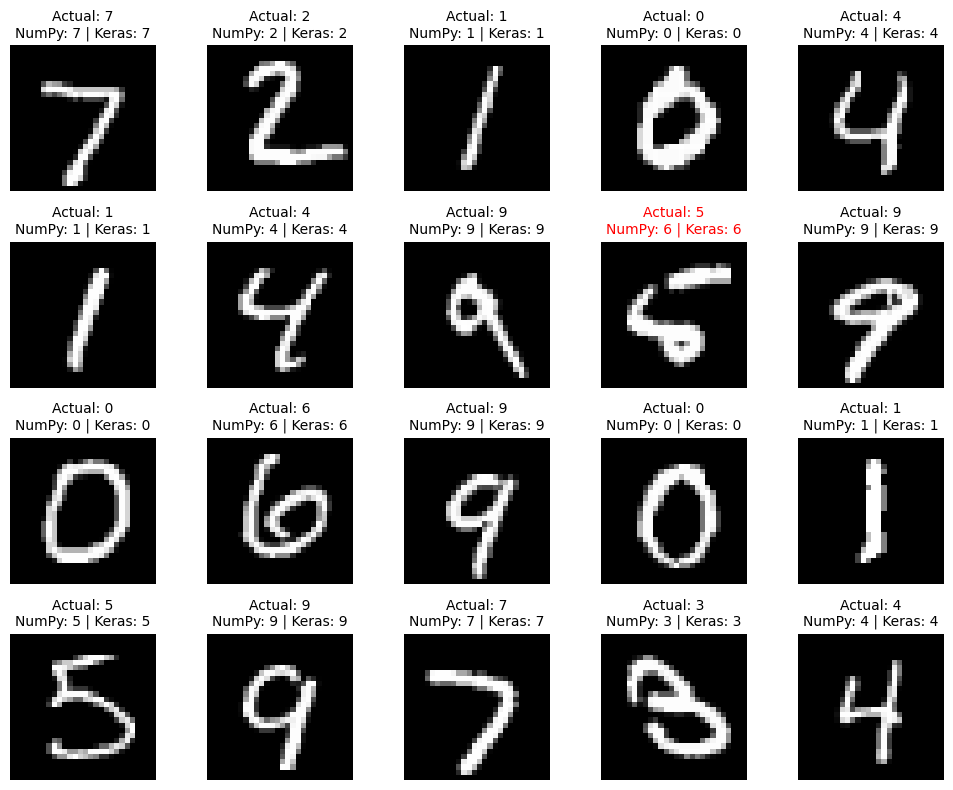

In [11]:
fig, axes = plt.subplots(4, 5, figsize=(10, 8))
for sample, ax in enumerate(axes.flat):
    actual = y_test[sample]
    numpy_prediction = numpy_test_predictions[sample]
    keras_prediction = keras_test_predictions[sample]
    correct = numpy_prediction == actual and keras_prediction == actual

    ax.imshow(X_test[sample].reshape(28, 28), cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"Actual: {actual}\nNumPy: {numpy_prediction} | Keras: {keras_prediction}",
                 color="black" if correct else "red", fontsize=10)
    ax.axis("off")

plt.tight_layout()
plt.show()
plt.close(fig)

### Results

Summarize the training and testing accuracy for both approaches.

In [12]:
print(f"After {epochs} epochs on {len(X_train):,} training images:")
print(f"NumPy training accuracy: {train_acc_list[-1]:.2%}")
print(f"NumPy testing accuracy:  {numpy_test_accuracy:.2%}")
print(f"Keras training accuracy: {keras_train_acc_list[-1]:.2%}")
print(f"Keras testing accuracy:  {keras_test_accuracy:.2%}")
print(f"Absolute test accuracy difference: "
      f"{abs(numpy_test_accuracy - keras_test_accuracy) * 100:.2f} percentage points")
print(f"NumPy loss decreased from {train_loss_list[0]:.4f} after epoch 1 "
      f"to {train_loss_list[-1]:.4f} after epoch {epochs}.")
print(f"Keras loss decreased from {keras_train_loss_list[0]:.4f} after epoch 1 "
      f"to {keras_train_loss_list[-1]:.4f} after epoch {epochs}.")

After 10 epochs on 60,000 training images:
NumPy training accuracy: 98.30%
NumPy testing accuracy:  97.21%
Keras training accuracy: 98.31%
Keras testing accuracy:  97.25%
Absolute test accuracy difference: 0.04 percentage points
NumPy loss decreased from 0.2853 after epoch 1 to 0.0620 after epoch 10.
Keras loss decreased from 0.2853 after epoch 1 to 0.0621 after epoch 10.


### References

- Assignment 07 code assistance
- [MNIST](https://www.tensorflow.org/api_docs/python/tf/keras/datasets/mnist/load_data)
- [Dense](https://www.tensorflow.org/api_docs/python/tf/keras/layers/Dense)
- [SGD](https://www.tensorflow.org/api_docs/python/tf/keras/optimizers/SGD)